# Réseau de neurones simple avec Keras

Dans cette démonstration, nous construisons avec Keras des réseaux de neurones qui reconnaissent les chiffres manuscrits de MNIST :

1. une régression logistique multinomiale, le réseau sans couche cachée, et l'accord entre sa sortie et sa perte ;
2. un perceptron multicouche régularisé ;
3. le suivi de l'entraînement avec TensorBoard, l'arrêt précoce et la sauvegarde du meilleur modèle ;
4. une recherche d'hyper-paramètres avec KerasTuner.

Il n'est pas nécessaire d'utiliser une carte graphique pour cette démonstration : chaque entraînement est rapide sur CPU, et seule la recherche d'hyper-paramètres, la dernière partie, prend quelques minutes. Vous pouvez donc changer d'environnement si celui qui vous a été attribué a une carte graphique (`Exécution > Modifier le type d'exécution`).

In [1]:
!pip install -q keras-tuner
import keras
import keras_tuner
import matplotlib.pyplot as plt
import numpy as np
from keras import layers

# Mêmes tirages aléatoires à chaque exécution : des résultats reproductibles
keras.utils.set_random_seed(0)

## Récupération des données

Cette fois, nous récupérons le jeu de données par Keras.

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

## Regardons les données

Commençons par la façon dont sont stockées les données : la forme et le type des quatre tableaux, la valeur des premières étiquettes, l'intervalle des pixels et le nombre d'exemples de chaque classe.

In [3]:
print(f"Format de X_train : {X_train.shape}, de X_test : {X_test.shape}")
print(f"Format de y_train : {y_train.shape}, de y_test : {y_test.shape}")
print(f"Type des images : {X_train.dtype}, de {X_train.min()} à {X_train.max()}")
print(f"Type des étiquettes : {y_train.dtype}, premières : {y_train[:10]}")
print(f"Exemples par classe : {np.bincount(y_train)}")

Format de X_train : (60000, 28, 28), de X_test : (10000, 28, 28)
Format de y_train : (60000,), de y_test : (10000,)
Type des images : uint8, de 0 à 255
Type des étiquettes : uint8, premières : [5 0 4 1 9 2 1 3 1 4]
Exemples par classe : [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


Nous avons 60 000 images d'entraînement et 10 000 de test, de 28 × 28 pixels : des entiers non signés sur 8 bits (`uint8`), de 0 à 255. Les étiquettes sont des entiers, de 0 à 9. Chaque classe compte de 5 421 à 6 742 exemples : les classes sont à peu près équilibrées.

Voici les dix premières images, avec leur étiquette.

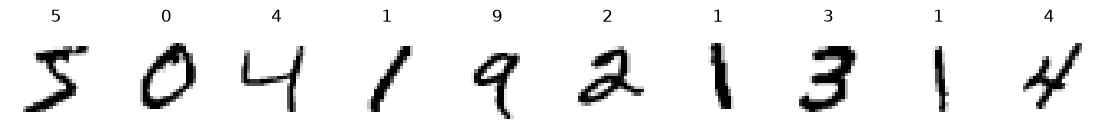

In [4]:
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for i, ax in enumerate(axes):
  ax.imshow(X_train[i], cmap="gray_r")
  ax.set_title(y_train[i])
  ax.axis("off")
plt.show()

## Transformation des données

Nous devons transformer ces données :

1. Aplatir les images : un tableau de forme `(_, 784)` plutôt que `(_, 28, 28)`, où `_` est le nombre d'exemples. Chaque image devient un vecteur de 784 pixels, l'entrée attendue par une couche `Dense`.
2. Ramener les pixels dans l'intervalle $[0, 1]$ plutôt que $[0, 255]$.
3. Encoder les classes en [*one-hot*](https://fr.wikipedia.org/wiki/Encodage_one-hot) : la première des deux pertes que nous verrons, `categorical_crossentropy`, attend pour chaque exemple 10 valeurs, toutes nulles sauf un 1 à l'indice de sa classe.

Nous gardons `y_train` et `y_test`, et rangeons les classes encodées dans `Y_train` et `Y_test`.

In [5]:
nb_classes = 10
dim_entree = 28 * 28

# Des images « à plat » : l'entrée du réseau est un vecteur de input_dim pixels,
# dans [0, 1]. -1 laisse NumPy calculer le nombre d'exemples.
X_train = X_train.reshape(-1, dim_entree) / 255
X_test = X_test.reshape(-1, dim_entree) / 255

# Les classes en vecteurs one-hot, pour categorical_crossentropy
Y_train = keras.utils.to_categorical(y_train, num_classes=nb_classes)
Y_test = keras.utils.to_categorical(y_test, num_classes=nb_classes)
print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)
print(f"Étiquette {y_train[0]} en one-hot : {Y_train[0]}")

(60000, 784) (10000, 784) (60000, 10) (10000, 10)
Étiquette 5 en one-hot : [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## Régression logistique multinomiale

Le premier modèle n'a pas de couche cachée : une entrée `keras.Input` de `dim_entree` pixels, puis une couche `layers.Dense` de `nb_classes` neurones, avec l'activation softmax. Chaque neurone calcule une combinaison linéaire des pixels, et la softmax en fait 10 probabilités de somme 1 : c'est une régression logistique multinomiale.

In [6]:
modele = keras.Sequential(
  [keras.Input(shape=(dim_entree,)), layers.Dense(nb_classes, activation="softmax")]
)
modele.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

Une couche `Dense` a un poids par entrée et par neurone, plus un biais par neurone : 784 × 10 + 10 = 7 850 paramètres. `None` est la taille du batch, libre.

## Apprentissage

Nous compilons le modèle avec `compile` : l'optimiseur `"sgd"` (descente de gradient stochastique, pas d'apprentissage de 0,01), la perte `categorical_crossentropy`, qui prend les cibles one-hot `Y_train`, et la métrique `"accuracy"`. Nous l'entraînons ensuite avec `fit`, avec :

- 128 exemples par batch ;
- 10 epochs ;
- 20 % des données d'entraînement en validation (`validation_split`).

Enfin, la fonction `evalue` mesure sa perte et son accuracy sur le jeu de test. Ces chiffres servent de référence aux modèles suivants.

In [7]:
def evalue(modele: keras.Model, one_hot: bool = False) -> None:
  """Affiche la perte et l'accuracy de `model` sur le jeu de test.

  one_hot : True pour un modèle entraîné sur les cibles one-hot (Y_train).
  """
  perte, justesse = modele.evaluate(X_test, Y_test if one_hot else y_test, verbose=0)
  print(f"Test : perte {perte:.3f}, accuracy {justesse:.3f}")

In [8]:
# compile associe au modèle un optimiseur, une fonction de perte et des métriques
modele.compile(optimizer="sgd", loss="categorical_crossentropy", metrics=["accuracy"])

# fit entraîne le modèle compilé : une boucle d'entraînement complète
historique = modele.fit(
  X_train, Y_train, batch_size=128, epochs=10, validation_split=0.2
)
evalue(modele, one_hot=True)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6740 - loss: 1.3776 - val_accuracy: 0.8325 - val_loss: 0.8860
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8336 - loss: 0.7852 - val_accuracy: 0.8615 - val_loss: 0.6519
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8521 - loss: 0.6389 - val_accuracy: 0.8725 - val_loss: 0.5588
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8619 - loss: 0.5686 - val_accuracy: 0.8791 - val_loss: 0.5073
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8687 - loss: 0.5256 - val_accuracy: 0.8841 - val_loss: 0.4740
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8738 - loss: 0.4960 - val_accuracy: 0.8875 - val_loss: 0.4504
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8778 - loss: 0.4740 - val_accuracy: 0.8902 - val_loss: 0.4325
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8805 - loss: 0.4569 - val_accuracy: 0.

La régression logistique atteint 89,6 % d'accuracy en validation à la dernière epoch, et 89,5 % en test, pour une perte de test de 0,40.

## Accorder la sortie et la perte

La perte `sparse_categorical_crossentropy` calcule la même entropie croisée que `categorical_crossentropy`, mais à partir des étiquettes entières `y_train` : l'encodage one-hot devient inutile, et les modèles suivants s'en passent.

Elle attend par défaut des probabilités, la sortie d'une softmax. Une couche sans activation renvoie des *logits*, les scores bruts des classes : la perte `keras.losses.SparseCategoricalCrossentropy(from_logits=True)` applique alors elle-même la softmax, en un calcul plus stable.

Nous entraînons sur `y_train`, avec l'optimiseur `"adam"` et les réglages de la partie précédente, trois régressions logistiques : `modele_adam`, à la sortie softmax, avec la perte par défaut ; `modele_logits`, sans activation, avec `from_logits=True` ; et `modele_faux`, sans activation, avec la perte par défaut : la mauvaise paire.

In [9]:
def entraine(activation: str | None, perte: str | keras.losses.Loss) -> keras.Model:
  """Entraîne et évalue une régression logistique, avec Adam, sur y_train."""
  modele = keras.Sequential(
    [keras.Input(shape=(dim_entree,)), layers.Dense(nb_classes, activation=activation)]
  )
  modele.compile(optimizer="adam", loss=perte, metrics=["accuracy"])
  modele.fit(
    X_train, y_train, batch_size=128, epochs=10, validation_split=0.2, verbose=0
  )
  evalue(modele)
  return modele


# Bonne paire : une sortie softmax, la perte par défaut, sur des probabilités
modele_adam = entraine("softmax", "sparse_categorical_crossentropy")
# Bonne paire : une sortie sans activation, des logits, et from_logits=True
sur_logits = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
modele_logits = entraine(None, sur_logits)
# Mauvaise paire : des logits, que la perte par défaut lit comme des probabilités
modele_faux = entraine(None, "sparse_categorical_crossentropy")

Test : perte 0.271, accuracy 0.924
Test : perte 0.272, accuracy 0.924
Test : perte 2.298, accuracy 0.389


Les deux bonnes paires donnent les mêmes chiffres : 92,4 % en test, 3 points de plus que la régression logistique entraînée avec SGD, à architecture égale. La mauvaise paire n'atteint que 38,9 %, avec une perte de test bloquée à 2,30. Keras ne signale rien : des logits ont la forme et le type de probabilités. La perte par défaut borne chaque valeur entre $10^{-7}$ et $1 - 10^{-7}$ avant d'en prendre le logarithme : un logit négatif devient $10^{-7}$, un logit au-dessus de 1 presque 1, et le gradient s'annule pour ces valeurs.

L'autre mauvaise paire, une sortie softmax avec `from_logits=True`, Keras la repère sous TensorFlow : il prévient (`UserWarning`) et reprend les logits d'avant la softmax.

## Perceptron multicouche régularisé

La fonction `construit_modele_profond` renvoie un perceptron multicouche neuf, non compilé :

- 4 couches cachées de 20 neurones, avec l'activation ReLU ;
- sur leurs poids, l'initialisation de He (`kernel_initializer`), adaptée à ReLU, et une pénalité L2 de coefficient $10^{-4}$ (`kernel_regularizer`) : une option de la couche, qui ajoute à la perte la somme des carrés de ses poids pour freiner le sur-apprentissage ;
- la même couche de sortie softmax que la régression logistique.

Nous en créons un, `modele_profond`, compilé avec l'optimiseur `"adam"`, la perte `sparse_categorical_crossentropy` et l'accuracy, et entraîné avec les mêmes réglages que la régression logistique, pour le comparer à `modele_adam`, la régression logistique entraînée avec le même optimiseur. Les parties suivantes réutilisent `construit_modele_profond`.

In [10]:
def construit_modele_profond() -> keras.Model:
  """Un perceptron multicouche neuf : 4 couches cachées régularisées de 20 neurones."""
  options_cachees = dict(
    activation="relu",
    kernel_regularizer=keras.regularizers.L2(1e-4),
    kernel_initializer="he_normal",
  )
  return keras.Sequential(
    [
      keras.Input(shape=(dim_entree,)),
      layers.Dense(20, **options_cachees),
      layers.Dense(20, **options_cachees),
      layers.Dense(20, **options_cachees),
      layers.Dense(20, **options_cachees),
      layers.Dense(nb_classes, activation="softmax"),
    ],
    name="modele_profond",
  )


modele_profond = construit_modele_profond()
modele_profond.summary()
modele_profond.compile(
  optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
modele_profond.fit(X_train, y_train, batch_size=128, epochs=10, validation_split=0.2)
evalue(modele_profond)

Model: "modele_profond"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 20)             │        15,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,170 (67.07 KB)

 Trainable params: 17,170 (67.07 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7790 - loss: 0.7261 - val_accuracy: 0.9088 - val_loss: 0.3363
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9178 - loss: 0.3077 - val_accuracy: 0.9358 - val_loss: 0.2536
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9344 - loss: 0.2493 - val_accuracy: 0.9408 - val_loss: 0.2287
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9424 - loss: 0.2208 - val_accuracy: 0.9434 - val_loss: 0.2154
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9480 - loss: 0.2010 - val_accuracy: 0.9465 - val_loss: 0.2033
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9523 - loss: 0.1858 - val_accuracy: 0.9500 - val_loss: 0.1962
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9559 - loss: 0.1735 - val_accuracy: 0.9495 - val_loss: 0.1916
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9584 - loss: 0.1633 - val_accuracy: 0.

`modele_profond` atteint 95,0 % en test, 2,6 points de plus que `modele_adam` (92,4 %), pour 17 170 paramètres au lieu de 7 850 : le gain de l'architecture seule, à optimiseur égal. Contre la régression logistique entraînée avec SGD, les 5,5 points d'écart mêlent architecture et optimiseur.

À la dernière epoch, l'accuracy d'entraînement (96,3 %) dépasse celle de validation (94,7 %), et `val_loss` remonte depuis l'epoch 7 : un début de sur-apprentissage, que la pénalité L2 n'empêche pas à elle seule. La partie « Arrêt précoce » arrête l'entraînement à temps ; la partie TensorBoard compare d'abord Adam et SGD sur ce modèle.

## Adam contre SGD sous TensorBoard

TensorBoard affiche les courbes d'apprentissage qu'un callback [`keras.callbacks.TensorBoard`](https://keras.io/api/callbacks/tensorboard/), passé à `fit`, écrit dans un dossier : un sous-dossier par entraînement.

Nous entraînons deux perceptrons multicouches neufs (`construit_modele_profond()`) avec les réglages de la partie « Perceptron multicouche régularisé », l'un avec l'optimiseur `"adam"`, l'autre avec `"sgd"`. Chaque `fit` reçoit un callback qui écrit dans `logs/adam` pour le premier, dans `logs/sgd` pour le second.

In [11]:
for optimiseur in ["adam", "sgd"]:
  modele = construit_modele_profond()
  modele.compile(
    optimizer=optimiseur, loss="sparse_categorical_crossentropy", metrics=["accuracy"]
  )
  tensorboard = keras.callbacks.TensorBoard(log_dir=f"logs/{optimiseur}")
  modele.fit(
    X_train,
    y_train,
    batch_size=128,
    epochs=10,
    validation_split=0.2,
    callbacks=[tensorboard],
  )

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.7794 - loss: 0.7051 - val_accuracy: 0.9120 - val_loss: 0.3102
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9218 - loss: 0.2782 - val_accuracy: 0.9308 - val_loss: 0.2485
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9379 - loss: 0.2252 - val_accuracy: 0.9391 - val_loss: 0.2186
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9471 - loss: 0.1972 - val_accuracy: 0.9444 - val_loss: 0.2015
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9523 - loss: 0.1789 - val_accuracy: 0.9499 - val_loss: 0.1913
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9560 - loss: 0.1652 - val_accuracy: 0.9517 - val_loss: 0.1857
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9595 - loss: 0.1546 - val_accuracy: 0.9532 - val_loss: 0.1791
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9626 - loss: 0.1460 - val_accuracy

La cellule suivante ouvre le tableau de bord, qui ne s'affiche que dans une session en cours : il faut exécuter le notebook pour le voir.

In [12]:
%load_ext tensorboard
%tensorboard --logdir logs

Dans l'onglet *Scalars*, les courbes `epoch_loss` et `epoch_accuracy` superposent les deux entraînements ; `train` et `validation` séparent les courbes d'entraînement et de validation.

Elles montrent ce que disent les journaux de `fit` ci-dessus : Adam converge bien plus vite. Il dépasse 90 % d'accuracy en validation dès la première epoch (91,2 %) et finit à 95,6 %, quand SGD part de 50,8 %, n'y arrive qu'à la neuvième epoch et finit à 91,1 %. SGD multiplie le gradient de chaque poids par le même pas d'apprentissage (0,01) ; Adam adapte le pas de chaque poids à la taille de ses gradients récents, et garde une inertie d'un pas à l'autre (la moyenne des gradients).

## Arrêt précoce et sauvegarde du meilleur modèle

Plutôt que de fixer le nombre d'epochs à l'avance, on arrête l'entraînement quand la perte de validation ne baisse plus. Deux callbacks s'en chargent, mais ne gardent pas la même chose.

Nous entraînons un perceptron multicouche neuf avec Adam, sur 50 epochs au plus, avec deux callbacks :

- `keras.callbacks.EarlyStopping` : arrêt après 3 epochs sans baisse de `val_loss`, **sans** `restore_best_weights` ;
- `keras.callbacks.ModelCheckpoint` : sauvegarde du modèle dans `meilleur.keras`, chaque fois que `val_loss` atteint un nouveau minimum.

Nous traçons ensuite `loss` et `val_loss`, d'après l'historique que renvoie `fit`, avec l'epoch du modèle sauvegardé, puis comparons sur le test le modèle en mémoire et le modèle rechargé avec `keras.models.load_model`.

Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.7685 - loss: 0.7334 - val_accuracy: 0.9172 - val_loss: 0.3085
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9246 - loss: 0.2793 - val_accuracy: 0.9379 - val_loss: 0.2338
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9400 - loss: 0.2253 - val_accuracy: 0.9438 - val_loss: 0.2139
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9469 - loss: 0.1983 - val_accuracy: 0.9458 - val_loss: 0.2044
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9525 - loss: 0.1798 - val_accuracy: 0.9463 - val_loss: 0.2003
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9565 - loss: 0.1663 - val_accuracy: 0.9479 - val_loss: 0.1991
Epoch 7/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9589 - loss: 0.1560 - val_accuracy: 0.9480 - val_loss: 0.1993
Epoch 8/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9616 - loss: 0.1483 - val_accu

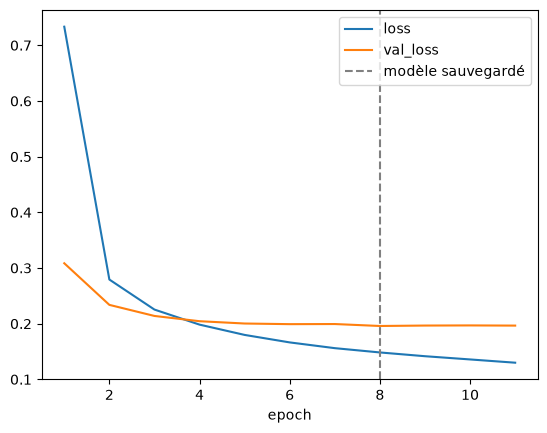

Modèle en mémoire :
Test : perte 0.187, accuracy 0.952
Modèle sauvegardé :
Test : perte 0.186, accuracy 0.952


In [13]:
# Graine remise avant de tirer les poids : les cellules précédentes ne comptent plus
keras.utils.set_random_seed(0)
modele = construit_modele_profond()
modele.compile(
  optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
rappels = [
  # Arrêt après 3 epochs sans baisse de val_loss : le modèle en mémoire garde les
  # poids de la dernière epoch
  keras.callbacks.EarlyStopping(monitor="val_loss", patience=3),
  # Sauvegarde du modèle à chaque nouveau minimum de val_loss
  keras.callbacks.ModelCheckpoint(
    "meilleur.keras", monitor="val_loss", save_best_only=True
  ),
]
historique = modele.fit(
  X_train,
  y_train,
  batch_size=128,
  epochs=50,
  validation_split=0.2,
  callbacks=rappels,
)
nb_epochs = len(historique.history["loss"])
# Le minimum de val_loss : l'epoch que ModelCheckpoint a sauvegardée en dernier
epoch_sauvegardee = int(np.argmin(historique.history["val_loss"])) + 1
print(f"Epochs effectuées : {nb_epochs}, epoch sauvegardée : {epoch_sauvegardee}")

epochs = range(1, nb_epochs + 1)
plt.plot(epochs, historique.history["loss"], label="loss")
plt.plot(epochs, historique.history["val_loss"], label="val_loss")
plt.axvline(epoch_sauvegardee, color="gray", linestyle="--", label="modèle sauvegardé")
plt.xlabel("epoch")
plt.legend()
plt.show()

print("Modèle en mémoire :")
evalue(modele)
print("Modèle sauvegardé :")
modele_sauvegarde = keras.models.load_model("meilleur.keras")
evalue(modele_sauvegarde)

L'entraînement s'arrête à l'epoch 11, 3 epochs après le minimum de `val_loss` (epoch 8), celle de `meilleur.keras`. Le modèle en mémoire garde les poids de la dernière epoch, le modèle rechargé ceux du minimum : ici, leurs chiffres de test sont presque les mêmes (95,2 % tous deux, une perte de 0,187 contre 0,186), `val_loss` remontant à peine en 3 epochs, mais rien ne garantit qu'ils le soient.

`EarlyStopping` décide quand s'arrêter, `ModelCheckpoint` garde sur disque le meilleur modèle vu ; `restore_best_weights=True` remettrait aussi en mémoire les poids de l'epoch 8. Sur la courbe, `loss` baisse encore quand `val_loss` ne baisse plus : le début du sur-apprentissage.

## Recherche d'hyper-paramètres

Combien de neurones dans la couche cachée, quel pas d'apprentissage ? KerasTuner essaie des combinaisons d'hyper-paramètres et garde la meilleure, notée sur le jeu de validation.

La fonction `construit_modele(hp)` renvoie un perceptron à une couche cachée ReLU, compilé avec Adam, la perte `sparse_categorical_crossentropy` et l'accuracy. Elle lit ses hyper-paramètres dans `hp` :

- `unites`, le nombre de neurones cachés : de 32 à 512, par pas de 32 ;
- `taux_apprentissage`, le pas d'apprentissage d'Adam : de $10^{-4}$ à $10^{-2}$, en échelle logarithmique.

La recherche passe par `keras_tuner.BayesianOptimization` : objectif `val_accuracy`, 5 essais, chacun entraîné 3 fois pour une moyenne moins bruitée, 10 epochs par entraînement, des batchs de 1 500 exemples et 20 % de validation. Nous comparons enfin le meilleur modèle à `modele_profond`. C'est la partie la plus longue : quelques minutes sur CPU.

In [14]:
def construit_modele(hp: keras_tuner.HyperParameters) -> keras.Model:
  # Chaque appel de hp lit la valeur que le tuner a choisie pour l'essai en cours
  unites = hp.Int("unites", min_value=32, max_value=512, step=32)
  taux_apprentissage = hp.Float(
    "taux_apprentissage", min_value=1e-4, max_value=1e-2, sampling="log"
  )
  modele = keras.Sequential(
    [
      keras.Input(shape=(dim_entree,)),
      layers.Dense(unites, activation="relu"),
      layers.Dense(nb_classes, activation="softmax"),
    ]
  )
  modele.compile(
    optimizer=keras.optimizers.Adam(taux_apprentissage),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
  )
  return modele


tuner = keras_tuner.BayesianOptimization(
  construit_modele,
  objective="val_accuracy",
  max_trials=5,
  executions_per_trial=3,
  seed=0,
  directory="tuner",
  project_name="mnist",
  overwrite=True,
)
tuner.search_space_summary()

Search space summary
Default search space size: 2
unites (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
taux_apprentissage (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.01, 'step': None, 'sampling': 'log'}


In [15]:
tuner.search(X_train, y_train, epochs=10, batch_size=1500, validation_split=0.2)

Trial 5 Complete [00h 01m 25s]
val_accuracy: 0.9753333330154419

Best val_accuracy So Far: 0.975777784983317
Total elapsed time: 00h 07m 45s


In [16]:
tuner.results_summary()
meilleur_modele = tuner.get_best_models()[0]
meilleur_modele.summary()
evalue(meilleur_modele)

Results summary
Results in tuner/mnist
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 2 summary
Hyperparameters:
unites: 384
taux_apprentissage: 0.009275112873609005
Score: 0.975777784983317

Trial 4 summary
Hyperparameters:
unites: 512
taux_apprentissage: 0.005008298972531056
Score: 0.9753333330154419

Trial 1 summary
Hyperparameters:
unites: 448
taux_apprentissage: 0.0011347233933337727
Score: 0.96875

Trial 0 summary
Hyperparameters:
unites: 192
taux_apprentissage: 0.0009265280882236007
Score: 0.9589166641235352

Trial 3 summary
Hyperparameters:
unites: 448
taux_apprentissage: 0.0004140284427504012
Score: 0.9551111062367758


.../site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 384)            │       301,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         3,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305,290 (1.16 MB)

 Trainable params: 305,290 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

Test : perte 0.074, accuracy 0.981


Le pas d'apprentissage compte plus que le nombre de neurones : les essais à moins de $1{,}2 \times 10^{-3}$ restent entre 95,5 % et 96,9 % en validation, ceux au-dessus de $5 \times 10^{-3}$ dépassent 97,5 %. Le meilleur essai (384 neurones, un pas d'apprentissage de $9{,}3 \times 10^{-3}$) atteint 97,6 % en validation et 98,1 % en test, mieux que `modele_profond` (95,0 %), avec 305 290 paramètres au lieu de 17 170. Avec des batchs de 1 500 exemples, 10 epochs ne font que 320 mises à jour des poids, contre 3 750 pour `modele_profond` : un petit pas n'a pas le temps de converger, quelle que soit la taille du modèle. Les essais tirés changent d'une exécution à l'autre ; quand ils n'ont que de petits pas, le meilleur modèle fait moins bien que `modele_profond`.

À l'exécution, `get_best_models` prévient qu'il ne recharge pas l'état de l'optimiseur (`Skipping variable loading for optimizer`) : les poids du modèle sont bien là, et ils suffisent pour l'évaluer.